# 02 – Cloud properties in ERA5

ERA5 provides several cloud variables (ECMWF, 2016 – IFS documentation; Hersbach et al., 2020):

| Short name | Meaning | Unit |
|---|---|---|
| `tcc` | total cloud cover – fraction of the grid box covered by cloud, seen from above | 0–1 |
| `lcc` | low cloud cover, below ~2 km (pressure > 0.8 × surface pressure) | 0–1 |
| `mcc` | medium cloud cover, ~2–6 km (0.45–0.8 × surface pressure) | 0–1 |
| `hcc` | high cloud cover, above ~6 km (< 0.45 × surface pressure) | 0–1 |
| `tclw` | total column cloud **liquid** water ("liquid water path") | kg m⁻² |
| `tciw` | total column cloud **ice** water ("ice water path") | kg m⁻² |
| `tcwv` | total column water **vapour** (precipitable water) | kg m⁻² |

Note that `tcc` is not the sum of the three layers: clouds at different levels
overlap when seen from above.

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np

from helpers import COLORS, GREY, PLATE, map_axes, open_era5, plot_field, save

ds = open_era5()
lsm = ds.lsm.isel(time=0)          # land-sea mask does not change in time
ds = ds.drop_vars("lsm")
ds[["tcc", "lcc", "mcc", "hcc", "tclw", "tciw", "tcwv"]].mean().compute()

<xarray.Dataset> Size: 28B
Dimensions:  ()
Data variables:
    tcc      float32 4B 0.4847
    lcc      float32 4B 0.1573
    mcc      float32 4B 0.2275
    hcc      float32 4B 0.3448
    tclw     float32 4B 0.02811
    tciw     float32 4B 0.02457
    tcwv     float32 4B 14.13
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-21T18:08 GRIB to CDM+CF via cfgrib-0.9.1...

## 1. Cloud cover at three levels

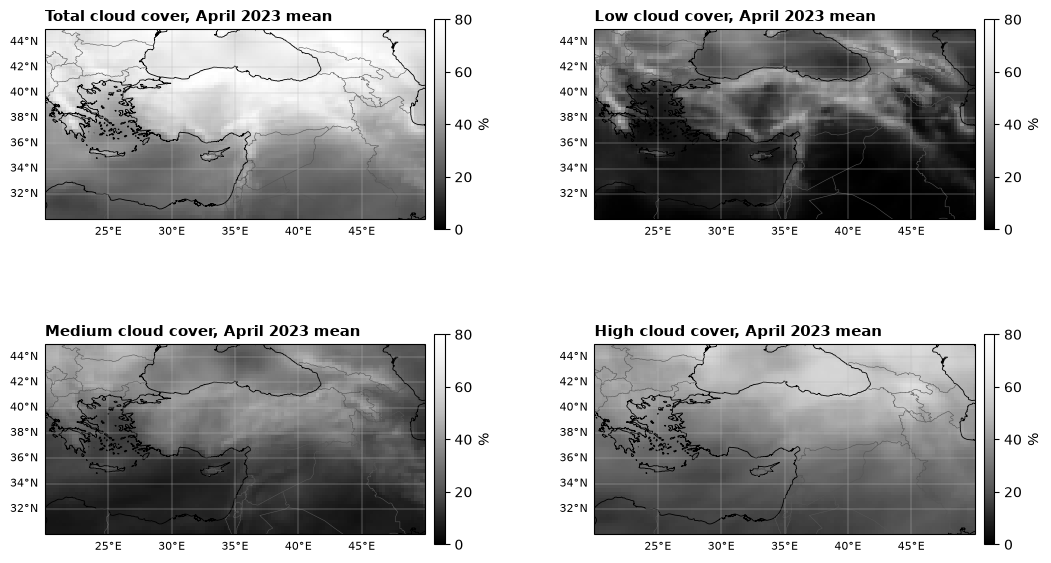

In [2]:
fig, axes = map_axes(2, 2, figsize=(13, 7.5))
for ax, var, title in zip(axes.flat, ["tcc", "lcc", "mcc", "hcc"],
                          ["Total", "Low", "Medium", "High"]):
    plot_field(ds[var].mean("time") * 100, ax, cmap="Greys_r", label="%", vmin=0, vmax=80)
    ax.set_title(f"{title} cloud cover, April 2023 mean")
save(fig, "02_cloud_cover_levels.png")

High clouds are the most frequent type in April (34 % mean cover, against 23 %
for medium and 16 % for low clouds). They are mostly cirrus associated with the
jet stream and passing frontal systems. Low clouds follow the **mountain ranges**
(Pontic mountains along the Black Sea, Taurus, Caucasus, Zagros) because air is
lifted and cooled there. Over the open seas and the deserts in the south there
are very few low clouds, and the total cloud cover is smallest.

## 2. Liquid vs. ice in the clouds

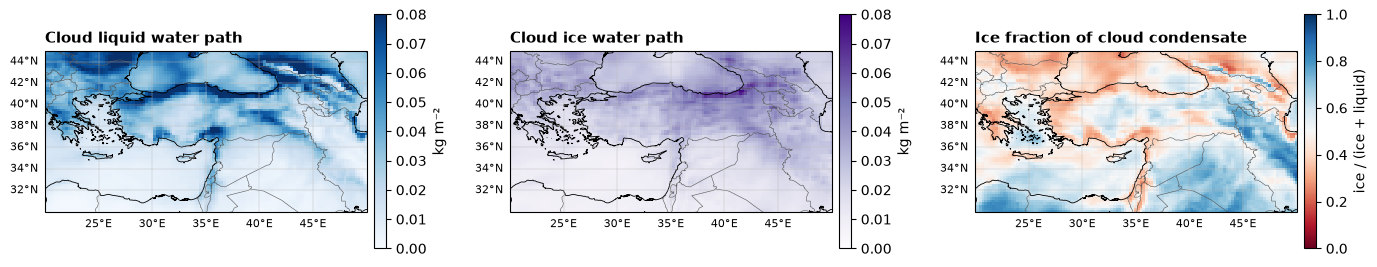

In [3]:
fig, axes = map_axes(1, 3, figsize=(17, 3.8))
plot_field(ds.tclw.mean("time"), axes[0], cmap="Blues", label="kg m⁻²", vmin=0, vmax=0.08)
axes[0].set_title("Cloud liquid water path")
plot_field(ds.tciw.mean("time"), axes[1], cmap="Purples", label="kg m⁻²", vmin=0, vmax=0.08)
axes[1].set_title("Cloud ice water path")
ice_frac = ds.tciw.mean("time") / (ds.tclw.mean("time") + ds.tciw.mean("time"))
plot_field(ice_frac, axes[2], cmap="RdBu", label="ice / (ice + liquid)", vmin=0, vmax=1)
axes[2].set_title("Ice fraction of cloud condensate")
save(fig, "02_liquid_ice_water_path.png")

Liquid water is found where low and medium clouds are common: over the Black
Sea, the Balkans and the mountain ranges. The ice fraction is highest over the
deserts in the south and south-east. This is not because it is colder there:
these areas have almost no low clouds, so the little condensate that exists is
in high cirrus clouds, which are made of ice. The ice fraction therefore tells us
mainly **at which height** the clouds are, because temperature falls with height.

## 3. Diurnal cycle of clouds: land vs. sea

We use the land-sea mask (`lsm` > 0.5 → land) with `.where()` to separate
land and sea points, then average by hour of the day.

land maximum at 13 UTC;  sea maximum at 4 UTC


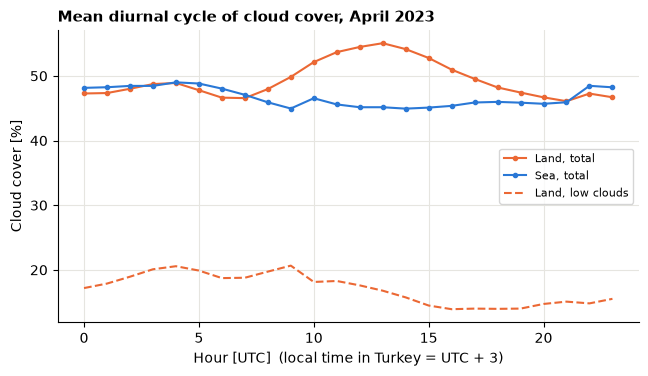

In [4]:
land = ds.tcc.where(lsm > 0.5).mean(["latitude", "longitude"]).groupby("time.hour").mean()
sea = ds.tcc.where(lsm < 0.5).mean(["latitude", "longitude"]).groupby("time.hour").mean()
land_l = ds.lcc.where(lsm > 0.5).mean(["latitude", "longitude"]).groupby("time.hour").mean()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(land.hour, land * 100, color=COLORS[1], marker="o", ms=3, label="Land, total")
ax.plot(sea.hour, sea * 100, color=COLORS[0], marker="o", ms=3, label="Sea, total")
ax.plot(land_l.hour, land_l * 100, color=COLORS[1], ls="--", label="Land, low clouds")
ax.set_xlabel("Hour [UTC]  (local time in Turkey = UTC + 3)")
ax.set_ylabel("Cloud cover [%]")
ax.set_title("Mean diurnal cycle of cloud cover, April 2023")
ax.legend(fontsize=8)
save(fig, "02_cloud_diurnal_cycle.png")
print("land maximum at", int(land.idxmax()), "UTC;  sea maximum at", int(sea.idxmax()), "UTC")

Over land, cloud cover peaks in the **early afternoon** (around 13 UTC = 16 local
time). The sun heats the ground, the air near the surface becomes unstable,
thermals rise and form convective (cumulus) clouds. The sea surface hardly warms
during the day, so over the sea the cycle is weak, with a small maximum at
night and in the early morning.

Low clouds over land do **not** peak in the afternoon; they are most frequent in
the morning (fog and stratus after the cold night) and decrease when the ground
warms. The afternoon convective clouds grow tall and are counted mostly as
medium and high cloud.

## 4. Do more clouds mean more rain?

We take all hourly values over the region and group the precipitation by the
total amount of cloud condensate (liquid + ice water path).
`np.digitize` puts each value into a bin.

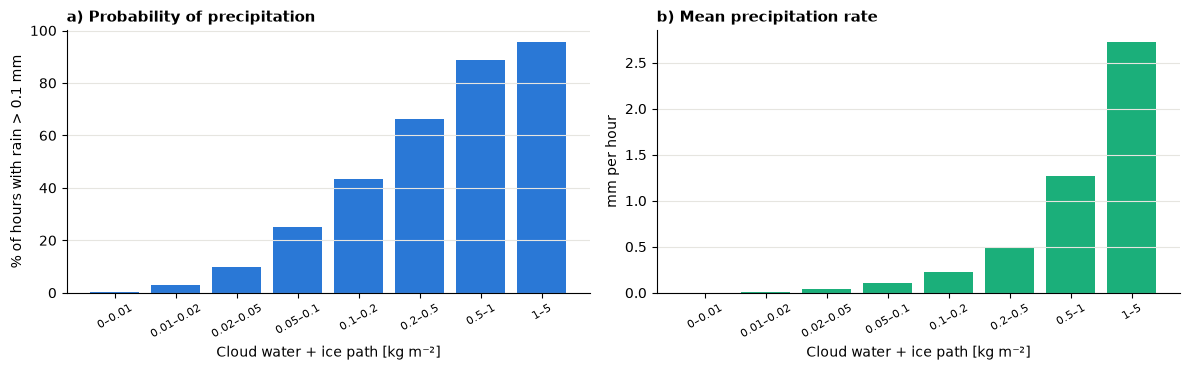

In [5]:
cwp = (ds.tclw + ds.tciw).values.ravel()
rain = (ds.tp * 1000).values.ravel()
bins = np.array([0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 5.0])
idx = np.digitize(cwp, bins) - 1
centers, prob, mean_rain = [], [], []
for i in range(len(bins) - 1):
    sel = idx == i
    if sel.sum() < 100:
        continue
    centers.append(f"{bins[i]:g}–{bins[i + 1]:g}")
    prob.append(100 * np.mean(rain[sel] > 0.1))
    mean_rain.append(rain[sel].mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(centers, prob, color=COLORS[0])
axes[0].set_ylabel("% of hours with rain > 0.1 mm")
axes[0].set_title("a) Probability of precipitation")
axes[1].bar(centers, mean_rain, color=COLORS[2])
axes[1].set_ylabel("mm per hour")
axes[1].set_title("b) Mean precipitation rate")
for ax in axes:
    ax.set_xlabel("Cloud water + ice path [kg m⁻²]")
    ax.tick_params(axis="x", labelsize=8, rotation=30)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_cloud_water_vs_rain.png")

The chance of rain rises quickly with the amount of condensed water in the
column. Thin clouds (< 0.05 kg m⁻²) almost never rain, while thick clouds with
more than 0.5 kg m⁻² of liquid and ice produce rain most of the time. This
agrees with the basic idea of cloud microphysics: rain only forms when droplets
and ice crystals have enough water to grow into falling drops.

## 5. Case study: the wettest day

Clouds and rain on the wettest day of the month (found in notebook 01).

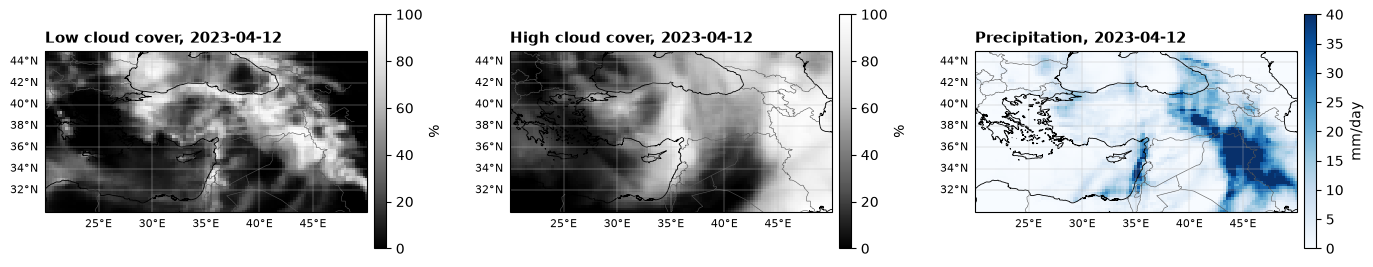

In [6]:
daily = ds.resample(time="1D").mean()
tp_daily = (ds.tp * 1000).resample(time="1D").sum()
wettest = tp_daily.mean(["latitude", "longitude"]).idxmax("time").dt.strftime("%Y-%m-%d").item()

fig, axes = map_axes(1, 3, figsize=(17, 3.8))
plot_field(daily.lcc.sel(time=wettest) * 100, axes[0], cmap="Greys_r", label="%", vmin=0, vmax=100)
axes[0].set_title(f"Low cloud cover, {wettest}")
plot_field(daily.hcc.sel(time=wettest) * 100, axes[1], cmap="Greys_r", label="%", vmin=0, vmax=100)
axes[1].set_title(f"High cloud cover, {wettest}")
plot_field(tp_daily.sel(time=wettest), axes[2], cmap="Blues", label="mm/day", vmax=40)
axes[2].set_title(f"Precipitation, {wettest}")
save(fig, "02_case_study_clouds.png")

**References:** Hersbach et al. (2020); ECMWF IFS Documentation CY41R2, Part IV:
Physical Processes (2016) for the cloud scheme and the definition of the cloud
layers; ERA5 parameter descriptions in the ECMWF Parameter Database. Full list in the README.